# Day 6: Transfer Learning with a Pretrained ResNet18
**Deep Learning Internship, Phase 2 (CNNs)**

A network pretrained on ImageNet already knows edges, textures and shapes, so we **reuse** it instead of training from zero.
- **Feature extraction:** freeze the pretrained layers, replace the last layer and train only that.
- **Fine-tuning:** also train the last pretrained block with a small learning rate.

We compare both with a CNN trained **from scratch** on the same 5,000 CIFAR-10 images.

> Use Colab with a **T4 GPU**. On a CPU, set `IMG_SIZE = 128` and `EPOCHS_TL = 3` to run faster. The first run downloads the ResNet18 weights (about 45 MB), so internet is needed.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms, models

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


## 1. Data: a small CIFAR-10 subset
Pretrained ResNet18 expects larger images with **ImageNet normalisation**, so for it we resize 32x32 to `IMG_SIZE` and use ImageNet mean/std.
The scratch CNN uses the original 32x32 images. Both use the **same** 5,000 training, 1,000 validation and 2,000 test images.

In [2]:
IMG_SIZE = 224                       # use 128 on a CPU
N_TRAIN, N_VAL, N_TEST = 5000, 1000, 2000
BATCH_SIZE = 64
EPOCHS_TL = 5                        # transfer learning epochs (use 3 on a CPU)
EPOCHS_SCRATCH = 15                  # scratch model needs more epochs (cheap at 32x32)

IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

big_tf = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.ToTensor(),
                             transforms.Normalize(IMNET_MEAN, IMNET_STD)])
small_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])

train_big = datasets.CIFAR10("./data", train=True, download=True, transform=big_tf)
test_big = datasets.CIFAR10("./data", train=False, download=True, transform=big_tf)
train_small = datasets.CIFAR10("./data", train=True, download=True, transform=small_tf)
test_small = datasets.CIFAR10("./data", train=False, download=True, transform=small_tf)
classes = train_big.classes

g = torch.Generator().manual_seed(42)
perm = torch.randperm(50000, generator=g).tolist()
train_idx = perm[:N_TRAIN]
val_idx = perm[N_TRAIN:N_TRAIN + N_VAL]
test_idx = torch.randperm(10000, generator=g).tolist()[:N_TEST]


def make_loaders(train_ds, test_ds):
    return (DataLoader(Subset(train_ds, train_idx), batch_size=BATCH_SIZE, shuffle=True),
            DataLoader(Subset(train_ds, val_idx), batch_size=BATCH_SIZE),
            DataLoader(Subset(test_ds, test_idx), batch_size=BATCH_SIZE))


train_loader_big, val_loader_big, test_loader_big = make_loaders(train_big, test_big)
train_loader_small, val_loader_small, test_loader_small = make_loaders(train_small, test_small)

print("train / val / test:", N_TRAIN, N_VAL, N_TEST)
x, _ = next(iter(train_loader_big))
print("pretrained input batch:", tuple(x.shape))

100%|██████████| 170M/170M [00:17<00:00, 9.93MB/s]


train / val / test: 5000 1000 2000
pretrained input batch: (64, 3, 224, 224)


## 2. Training helpers

In [3]:
def count_params(model, trainable_only=True):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))


def run_epoch(model, loader, criterion, optimizer=None, train_modules=None):
    """train_modules: names of child modules allowed to stay in train mode.
    Frozen parts stay in eval mode so their batch-norm statistics do not change."""
    training = optimizer is not None
    if training:
        model.train()
        if train_modules is not None:
            for name, child in model.named_children():
                if name not in train_modules:
                    child.eval()
    else:
        model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total


def fit(model, train_loader, val_loader, epochs, optimizer, train_modules=None):
    criterion = nn.CrossEntropyLoss()
    history = {"train_acc": [], "val_acc": []}
    best_val, best_state = 0.0, None
    start = time.time()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, train_modules)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        history["train_acc"].append(tr_acc); history["val_acc"].append(va_acc)
        if va_acc > best_val:
            best_val = va_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"Epoch {epoch:2d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
              f"| val loss {va_loss:.4f} acc {va_acc:.4f}")
    history["time"] = time.time() - start
    return history, best_state


results = {}


def finish(name, model, hist, state, test_loader):
    model.load_state_dict(state)
    _, test_acc = run_epoch(model, test_loader, nn.CrossEntropyLoss())
    results[name] = {"hist": hist, "test_acc": test_acc, "trainable": count_params(model)}
    print(f"Test accuracy: {test_acc:.4f} | trainable parameters: {count_params(model):,}")

## 3. Feature extraction: freeze everything, train only the new last layer
We load ResNet18 pretrained on ImageNet, replace the final layer (1000 classes -> 10) and freeze all other layers.

In [4]:
def make_resnet18(num_classes=10):
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m


fe_model = make_resnet18().to(device)
for name, p in fe_model.named_parameters():
    p.requires_grad = name.startswith("fc.")          # only the new last layer is trainable

print("total parameters:    ", f"{count_params(fe_model, trainable_only=False):,}")
print("trainable parameters:", f"{count_params(fe_model):,}")

fe_opt = torch.optim.Adam([p for p in fe_model.parameters() if p.requires_grad], lr=1e-3)
hist, state = fit(fe_model, train_loader_big, val_loader_big, EPOCHS_TL, fe_opt, train_modules={"fc"})
finish("Feature extraction", fe_model, hist, state, test_loader_big)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 144MB/s]


total parameters:     11,181,642
trainable parameters: 5,130
Epoch  1/5 | train loss 1.2224 acc 0.6464 | val loss 0.7526 acc 0.7820
Epoch  2/5 | train loss 0.6237 acc 0.8238 | val loss 0.5807 acc 0.8260
Epoch  3/5 | train loss 0.5099 acc 0.8482 | val loss 0.5076 acc 0.8400
Epoch  4/5 | train loss 0.4499 acc 0.8650 | val loss 0.4855 acc 0.8450
Epoch  5/5 | train loss 0.4106 acc 0.8740 | val loss 0.4662 acc 0.8500
Test accuracy: 0.8540 | trainable parameters: 5,130


## 4. Fine-tuning: also train the last pretrained block (`layer4`)
`layer4` gets a **small** learning rate (1e-4) so the pretrained knowledge is adjusted gently, and the new layer gets a larger one (1e-3).

In [5]:
ft_model = make_resnet18().to(device)
for name, p in ft_model.named_parameters():
    p.requires_grad = name.startswith(("layer4", "fc."))

print("trainable parameters:", f"{count_params(ft_model):,}")

ft_opt = torch.optim.Adam([
    {"params": ft_model.layer4.parameters(), "lr": 1e-4},
    {"params": ft_model.fc.parameters(), "lr": 1e-3},
])
hist, state = fit(ft_model, train_loader_big, val_loader_big, EPOCHS_TL, ft_opt,
                  train_modules={"layer4", "fc"})
finish("Fine-tuning (layer4 + fc)", ft_model, hist, state, test_loader_big)

trainable parameters: 8,398,858
Epoch  1/5 | train loss 0.7126 acc 0.7734 | val loss 0.3491 acc 0.8900
Epoch  2/5 | train loss 0.1599 acc 0.9546 | val loss 0.3136 acc 0.8860
Epoch  3/5 | train loss 0.0431 acc 0.9956 | val loss 0.3021 acc 0.9110
Epoch  4/5 | train loss 0.0130 acc 1.0000 | val loss 0.2947 acc 0.9130
Epoch  5/5 | train loss 0.0102 acc 0.9994 | val loss 0.3074 acc 0.9100
Test accuracy: 0.8975 | trainable parameters: 8,398,858


## 5. Baseline: a CNN trained from scratch on the same 5,000 images

In [6]:
class SmallCNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()

        def block(i, o):
            return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]

        self.features = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(),
                                        nn.Dropout(dropout), nn.Linear(256, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


scratch = SmallCNN().to(device)
sc_opt = torch.optim.Adam(scratch.parameters(), lr=1e-3)
hist, state = fit(scratch, train_loader_small, val_loader_small, EPOCHS_SCRATCH, sc_opt)
finish("From scratch (32x32)", scratch, hist, state, test_loader_small)

Epoch  1/15 | train loss 1.8611 acc 0.3170 | val loss 1.5436 acc 0.4190
Epoch  2/15 | train loss 1.4854 acc 0.4578 | val loss 1.4531 acc 0.4560
Epoch  3/15 | train loss 1.3599 acc 0.5122 | val loss 1.2937 acc 0.5240
Epoch  4/15 | train loss 1.1885 acc 0.5824 | val loss 1.1730 acc 0.5880
Epoch  5/15 | train loss 1.0687 acc 0.6174 | val loss 1.1754 acc 0.5940
Epoch  6/15 | train loss 0.9947 acc 0.6486 | val loss 1.1624 acc 0.5790
Epoch  7/15 | train loss 0.8865 acc 0.6862 | val loss 1.1593 acc 0.5840
Epoch  8/15 | train loss 0.8153 acc 0.7122 | val loss 1.2338 acc 0.5910
Epoch  9/15 | train loss 0.7039 acc 0.7532 | val loss 1.2798 acc 0.5750
Epoch 10/15 | train loss 0.6676 acc 0.7620 | val loss 1.1391 acc 0.6140
Epoch 11/15 | train loss 0.5592 acc 0.7974 | val loss 1.0798 acc 0.6420
Epoch 12/15 | train loss 0.5056 acc 0.8200 | val loss 1.1667 acc 0.6540
Epoch 13/15 | train loss 0.4331 acc 0.8436 | val loss 1.1738 acc 0.6540
Epoch 14/15 | train loss 0.3725 acc 0.8688 | val loss 1.2441 acc

## 6. Comparison: accuracy and training time

Method                        Trainable params  Best val acc  Test acc  Time (s)
Feature extraction                       5,130        0.8500    0.8540      79.1
Fine-tuning (layer4 + fc)            8,398,858        0.9130    0.8975      82.3
From scratch (32x32)                   620,810        0.6540    0.6615      25.6


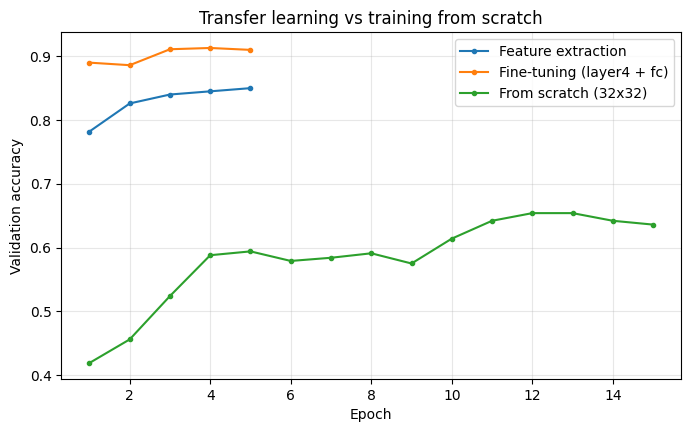

In [7]:
print(f"{'Method':<28} {'Trainable params':>17} {'Best val acc':>13} {'Test acc':>9} {'Time (s)':>9}")
for name, r in results.items():
    print(f"{name:<28} {r['trainable']:>17,} {max(r['hist']['val_acc']):>13.4f} "
          f"{r['test_acc']:>9.4f} {r['hist']['time']:>9.1f}")

plt.figure(figsize=(8, 4.5))
for name, r in results.items():
    plt.plot(range(1, len(r["hist"]["val_acc"]) + 1), r["hist"]["val_acc"], marker="o", markersize=3, label=name)
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy"); plt.title("Transfer learning vs training from scratch")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 7. Bonus: your own small dataset
Organise photos in **one folder per class**, for example:
```
my_dataset/
    class_a/  img1.jpg img2.jpg ...
    class_b/  img1.jpg ...
```
Set `CUSTOM_DIR` below. The cell trains a new last layer on a frozen ResNet18, exactly like section 3.

In [8]:
CUSTOM_DIR = None            # e.g. "my_dataset"

if CUSTOM_DIR:
    custom = datasets.ImageFolder(CUSTOM_DIR, transform=big_tf)
    print("classes:", custom.classes, "| images:", len(custom))
    n_val = max(1, int(0.2 * len(custom)))
    c_train, c_val = random_split(custom, [len(custom) - n_val, n_val],
                                  generator=torch.Generator().manual_seed(42))
    c_train_loader = DataLoader(c_train, batch_size=16, shuffle=True)
    c_val_loader = DataLoader(c_val, batch_size=16)

    c_model = make_resnet18(num_classes=len(custom.classes)).to(device)
    for name, p in c_model.named_parameters():
        p.requires_grad = name.startswith("fc.")
    c_opt = torch.optim.Adam([p for p in c_model.parameters() if p.requires_grad], lr=1e-3)
    fit(c_model, c_train_loader, c_val_loader, 10, c_opt, train_modules={"fc"})
else:
    print("Set CUSTOM_DIR to run the bonus section.")

Set CUSTOM_DIR to run the bonus section.


## Summary (rewrite in your own words)
- A network pretrained on ImageNet already knows general visual features (edges, textures, shapes), so it can be reused on a new task.
- **Feature extraction** trains only the new last layer; **fine-tuning** also trains some pretrained layers with a small learning rate.
- Frozen layers stay in `eval()` mode so their batch-norm statistics are not disturbed; new images must use the same **ImageNet normalisation** and a larger size.
- Compare the table: transfer learning usually reaches higher accuracy with far fewer trainable parameters than training from scratch, especially with little data. Note the training time per epoch too, because 224x224 images are much slower than 32x32.
- Next (Day 7): clean up the notebooks, write the README and push everything to GitHub.